- ***강의 출처: 딥러닝 CNN 완벽 가이드, 권철민 (인프런)***

<img src = "../Images/0f5b3ac6-023b-4009-8775-71fd3338d7c2.jpeg">

**filters** : **kernel**이 모인 형태(3차원) 
- 만약, kernel_size=3 (3x3 -> 2차원)이라면, 
- filter는 kernel들이 모인것이므로 2차원 X n개 (1차원 증가) : 3차원의 형태를 띄게 된다. 


In [1]:
import numpy as np
import pandas as pd
import os

In [2]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D
from tensorflow.keras.models import Model

# tf.keras의 input은 기본이 3차원. 
# grayscale(2차원)일 경우, 뒤에 채널(뒤의 1)까지 입력하여 3차원으로 만듦
input_tensor = Input(shape=(28, 28, 1)) 

x = Conv2D(filters=4, 
           kernel_size=3, # kernel은 기본적으로 정방행렬(3x3)
           strides=1, # 1칸씩 이동
           padding='same', # 연산을 적용한 결과의 shape가 input과 동일(크기 유지) 
           activation='relu')(input_tensor) # conv2d 연산에서는 입력값이 무조건 3차원이다.

print('x type:', type(x), 'x:', x)
# output

I0000 00:00:1792742649.825185      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792742649.829026      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


x type: <class 'keras.src.backend.common.keras_tensor.KerasTensor'> x: <KerasTensor shape=(None, 28, 28, 4), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1>


In [3]:
# Pooling 적용하기
input_tensor = Input(shape=(28, 28, 1))
x = Conv2D(filters=16, kernel_size=3, strides=1, padding='same', activation='relu')(input_tensor)
print('x type:',  type(x), 'x:', x)

x type: <class 'keras.src.backend.common.keras_tensor.KerasTensor'> x: <KerasTensor shape=(None, 28, 28, 16), dtype=float32, sparse=False, ragged=False, name=keras_tensor_3>


In [4]:
# CNN 모델 생성
input_tensor = Input(shape=(28, 28, 1))
x = Conv2D(filters=32, kernel_size=3, strides=1, padding='same', activation='relu')(input_tensor)
x = Conv2D(filters=64, kernel_size=3, activation='relu')(x)
x = MaxPooling2D(2)(x)

model = Model(inputs=input_tensor, outputs=x)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,816 (73.50 KB)

 Trainable params: 18,816 (73.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.layers import Input, Conv2D, MaxPool2D

input_tensor = Input(shape=(28,28,1))
x = Conv2D(filters=32, kernel_size=3, strides=1, 
           padding='same', activation='relu')(input_tensor)
x = Conv2D(filters=64, kernel_size=3, activation='relu')(input_tensor)
x = MaxPooling2D(2)(x)

# Feature Map결과를 Fully Connected Layer로 연결하기 위해 Flatten() 적용.
x = Flatten()(x)
x = Dense(100, activation='relu')(x)
output = Dense(10, activation='softmax')(x)
model = Model(inputs=input_tensor, outputs=output)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     1,081,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,083,350 (4.13 MB)

 Trainable params: 1,083,350 (4.13 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Fashoion MNIST 데이터 전처리 후 모델 학습
from tensorflow.keras.datasets import fashion_mnist
import numpy as np
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# MNIST dataset 로드
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

def get_preprocessed_data(images, labels):
    images = np.array(images/255.0, dtype=np.float32)
    labels = np.array(labels, dtype=np.float32)
    return images, labels

def get_preprocessed_ohe(images, labels):
    images, labels = get_preprocessed_data(images, labels)
    # 원-핫 인코더 적용
    oh_labels = to_categorical(labels)
    return images, oh_labels

# train/valid/test dataset에 preprocessing 및 one-hot encoding 적용
def get_train_valid_test_set(train_images, train_labels, 
                             test_images, test_labels, 
                             valid_size=0.15,
                             random_state=2021):
    # train/test dataset을 0~1 사이의 값과 float32로 변경 및 원-핫 인코딩 적용 
    train_images, train_oh_labels =  get_preprocessed_ohe(train_images, train_labels)
    test_images, test_oh_labels = get_preprocessed_ohe(test_images, test_labels)

    # train dataset을 train/valid dataset으로 다시 분리
    tr_images, val_images, tr_oh_labels, val_oh_labels = train_test_split(train_images, train_oh_labels,
                                                                             test_size=valid_size,
                                                                             random_state=random_state)
    
    return (tr_images, tr_oh_labels), (val_images, val_oh_labels), (test_images, test_oh_labels)

# MNIST 데이터 재로딩 및 전처리 적용, 데이터 세트 분리 함수 실행
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()
print(train_images.shape, train_labels.shape, test_images.shape, test_labels.shape)

(tr_images, tr_oh_labels), (val_images, val_oh_labels), (test_images, test_oh_labels) = \
      get_train_valid_test_set(train_images, train_labels,
                               test_images, test_labels,
                               valid_size=0.15, random_state=2021)
# 분리된 데이터 셋들의 shape 확인
print(tr_images.shape, tr_oh_labels.shape)
print(val_images.shape, val_oh_labels.shape)
print(test_images.shape, test_oh_labels)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
(51000, 28, 28) (51000, 10)
(9000, 28, 28) (9000, 10)
(10000, 28, 28) [[0. 0. 0. ... 0. 0. 1.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 1. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [7]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import Accuracy

model.compile(optimizer=Adam(0.001), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

In [8]:
history = model.fit(x=tr_images, y=tr_oh_labels, 
                    batch_size=128, epochs=30, 
                    validation_data=(val_images, val_oh_labels))

Epoch 1/30
 40/399 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5540 - loss: 1.2814

I0000 00:00:1792742686.051612     138 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


399/399 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8397 - loss: 0.4550 - val_accuracy: 0.8769 - val_loss: 0.3537
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8930 - loss: 0.3059 - val_accuracy: 0.8973 - val_loss: 0.2912
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9083 - loss: 0.2578 - val_accuracy: 0.9013 - val_loss: 0.2790
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9193 - loss: 0.2256 - val_accuracy: 0.9047 - val_loss: 0.2634
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9283 - loss: 0.1991 - val_accuracy: 0.9086 - val_loss: 0.2517
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9339 - loss: 0.1790 - val_accuracy: 0.9098 - val_loss: 0.2546
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9422 - loss: 0.1592 - val_accuracy: 0.9146 - val_loss: 0.2453
Epoch 8/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9487 - loss: 0.1404 - val_accuracy: 0.9148 - val

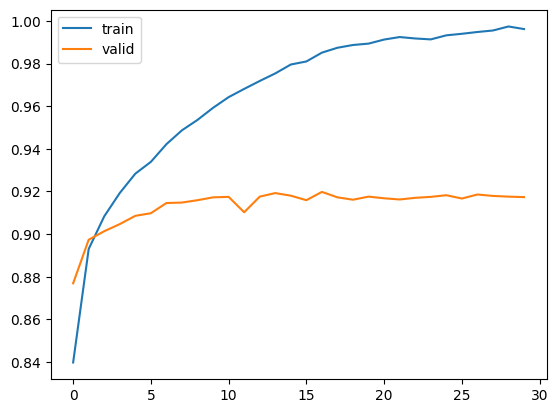

In [11]:
# 모델 성능 평가
import matplotlib.pyplot as plt
%matplotlib inline

def show_history(history):
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='valid')
    plt.legend()

show_history(history)    

In [12]:
model.evaluate(test_images, test_oh_labels, batch_size=256, verbose=1)

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9175 - loss: 0.4869


[0.4868831932544708, 0.9175000190734863]

In [ ]:
# dropout 적용하여 FCL(Fully Connected Layer)의 overfitting 조정
#   Flatten() --> Dropout() --> FCL() 의 순서

from tensorflow.keras.layers import Dense, Flatten, Dropout

input_tensor = Input(shape=(28, 28, 1))
x = Conv2D(filters=32, kernel_size=3, strides=1, padding='same', activation='relu')(input_tensor)
x = Conv2D(filters=64, kernel_size=3, activation='relu')(x)
x = MaxPool2D(2)(x)


x = Flatten()(x)
x = Dropout(rate=0.5)(x) 
x = Dense(100, activation='relu')(x)
output = Dense(10, activation='softmax')(x)
model = Model(inputs=input_tensor, outputs=output)
model.summary()




Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │     1,081,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,101,526 (4.20 MB)

 Trainable params: 1,101,526 (4.20 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x=tr_images, y=tr_oh_labels, 
                    batch_size=128, epochs=30, 
                    validation_data=(val_images, val_oh_labels))

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8358 - loss: 0.4618 - val_accuracy: 0.8872 - val_loss: 0.3207
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8905 - loss: 0.3023 - val_accuracy: 0.9018 - val_loss: 0.2737
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9095 - loss: 0.2523 - val_accuracy: 0.9081 - val_loss: 0.2534
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9201 - loss: 0.2184 - val_accuracy: 0.9198 - val_loss: 0.2207
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9275 - loss: 0.1950 - val_accuracy: 0.9228 - val_loss: 0.2157
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9355 - loss: 0.1736 - val_accuracy: 0.9258 - val_loss: 0.2040
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9415 - loss: 0.1552 - val_accuracy: 0.9262 - val_loss: 0.2090
Epoch 8/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9474 - loss: 0.1393 - val_accuracy: 0

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9292 - loss: 0.3474


[0.34736889600753784, 0.9291999936103821]

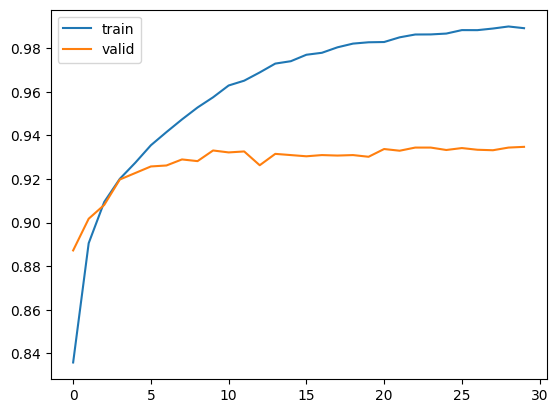

In [15]:
show_history(history)
model.evaluate(test_images, test_oh_labels, batch_size=256, verbose=1)

In [19]:
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D

def create_model():
    input_tensor = Input(shape=(28, 28, 1))
    x = Conv2D(filters=32, kernel_size=3, strides=1, padding='same', activation='relu')(input_tensor)
    x = Conv2D(filters=64, kernel_size=3, activation='relu')(x)
    x = MaxPool2D(2)(x)

    x = Flatten()(x)
    x = Dropout(rate=0.5)(x)  # 드롭아웃 1 (50%)
    x = Dense(200, activation='relu')(x) # dense를 200으로 늘림 
    x = Dropout(rate=0.2)(x)  # 드롭아웃 2 (20%)
    output = Dense(10, activation='softmax')(x)
    model = Model(inputs=input_tensor, outputs=output)
    model.summary()

    return model

model = create_model()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 200)            │     2,163,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,184,226 (8.33 MB)

 Trainable params: 2,184,226 (8.33 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x=tr_images, y=tr_oh_labels, 
                    batch_size=128, epochs=30, 
                    validation_data=(val_images, val_oh_labels))

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8354 - loss: 0.4581 - val_accuracy: 0.8839 - val_loss: 0.3206
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8921 - loss: 0.2962 - val_accuracy: 0.9049 - val_loss: 0.2597
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9080 - loss: 0.2500 - val_accuracy: 0.9117 - val_loss: 0.2419
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9193 - loss: 0.2182 - val_accuracy: 0.9183 - val_loss: 0.2227
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9285 - loss: 0.1921 - val_accuracy: 0.9242 - val_loss: 0.2095
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9359 - loss: 0.1718 - val_accuracy: 0.9297 - val_loss: 0.1992
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9430 - loss: 0.1526 - val_accuracy: 0.9286 - val_loss: 0.1998
Epoch 8/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9464 - loss: 0.1425 - val_accuracy: 0

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9283 - loss: 0.3193


[0.3193344175815582, 0.9283000230789185]

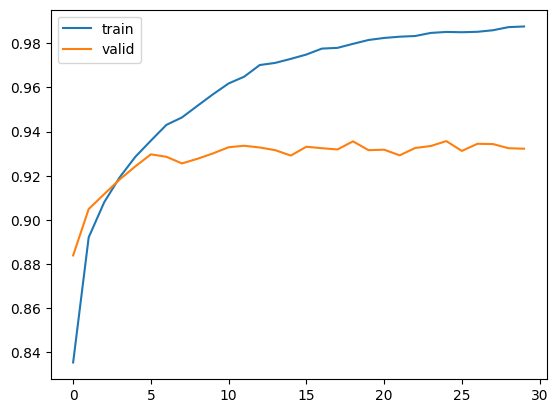

In [21]:
show_history(history)
model.evaluate(test_images, test_oh_labels, batch_size=256, verbose=1)

In [23]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()
print('before reshape(train images):', train_images.shape, train_labels.shape)
print('before reshape:(test images):', test_images.shape, test_labels.shape)

train_images = train_images.reshape(60000, 28, 28, 1)
test_images= test_images.reshape(10000, 28, 28, 1)
print('after reshape(train images):', train_images.shape, train_labels.shape)
print('after reshape(test images):', test_images.shape, test_labels.shape)

(tr_images, tr_oh_labels), (val_images, val_oh_labels), (test_images, test_oh_labels) = \
      get_train_valid_test_set(train_images, train_labels,
                               test_images, test_labels,
                               valid_size=0.15, random_state=2021)
# 분리된 데이터 셋들의 shape 확인
print(tr_images.shape, tr_oh_labels.shape)
print(val_images.shape, val_oh_labels.shape)
print(test_images.shape, test_oh_labels.shape)

before reshape(train images): (60000, 28, 28) (60000,)
before reshape:(test images): (10000, 28, 28) (10000,)
after reshape(train images): (60000, 28, 28, 1) (60000,)
after reshape(test images): (10000, 28, 28, 1) (10000,)
(51000, 28, 28, 1) (51000, 10)
(9000, 28, 28, 1) (9000, 10)
(10000, 28, 28, 1) (10000, 10)


In [24]:
model.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x=tr_images, y=tr_oh_labels, 
                    batch_size=128, epochs=30, 
                    validation_data=(val_images, val_oh_labels))

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9875 - loss: 0.0337 - val_accuracy: 0.9311 - val_loss: 0.3055
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9887 - loss: 0.0325 - val_accuracy: 0.9371 - val_loss: 0.3118
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9890 - loss: 0.0308 - val_accuracy: 0.9344 - val_loss: 0.3047
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9882 - loss: 0.0339 - val_accuracy: 0.9341 - val_loss: 0.2900
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9889 - loss: 0.0305 - val_accuracy: 0.9321 - val_loss: 0.3218
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9880 - loss: 0.0321 - val_accuracy: 0.9352 - val_loss: 0.3016
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9891 - loss: 0.0295 - val_accuracy: 0.9310 - val_loss: 0.3244
Epoch 8/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9897 - loss: 0.0298 - val_accuracy: 

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9304 - loss: 0.3840


[0.38404783606529236, 0.930400013923645]

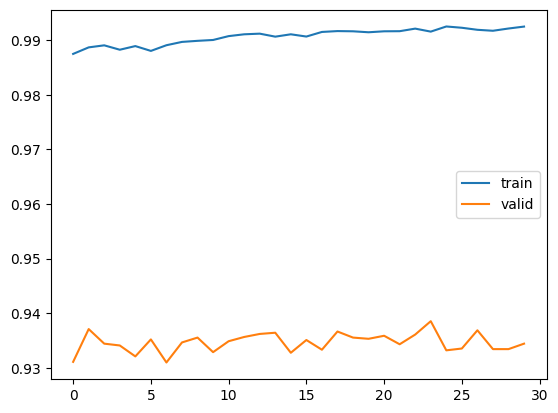

In [25]:
show_history(history)
model.evaluate(test_images, test_oh_labels, batch_size=256, verbose=1)